# M1 walkthrough: realistic-looking id swaps and three cheap baselines
Plumbing only: default parameters, nothing tuned (DEVELOPMENT.md §6 M1). The corruption is ours, so the question here is whether everything runs and explains itself, not whether ArbiterKB wins.

In [1]:
import sys, os
sys.path.insert(0, '..')
os.environ['ARBITER_DEBUG'] = '1'
import numpy as np
from arbiter_kb.sources.synthetic import SyntheticSource
from arbiter_kb.sources.realistic import OverlapSwapSource, NoisySource
from arbiter_kb.systems.arbiter_kb import ArbiterKBSystem
from arbiter_kb.systems.baselines import TrackerSystem, GuardedBound
from arbiter_kb.evaluate import run
from arbiter_kb.debug import explain
from arbiter_kb.params import Params
params = Params.load('../params.json')

In [2]:
# lane 'mix': each episode draws a sideways offset; small offsets make the two containers overlap
base = SyntheticSource(lane_offset='mix', swap_steps='mix')
[(ep, base.settings(ep)) for ep in base.episodes('train', 8)]

[(0, (0.02, 50)),
 (1, (0.02, 20)),
 (2, (0.01, 50)),
 (3, (0.07, 20)),
 (4, (0.02, 50)),
 (5, (0.0, 50)),
 (6, (0.0, 35)),
 (7, (0.07, 50))]

In [3]:
# id_swap_overlap: ids may swap only where the two tracks come within d_ov = 3 cm; the label jumps < d_ov
bad = OverlapSwapSource(base, p_swap=1.0, d_ov=params.baseline.d_ov)
ep = next(e for e in base.episodes('train', 40) if list(bad.frames(e)) and bad.log[e]['corrupted'])
base.settings(ep), bad.log[ep]

((0.01, 50),
 {'corrupted': True,
  'n_overlap_passes': 1,
  'n_passes': 1,
  'swaps': [[89, 'bin_0', 'bin_3', 0.02]],
  'label_jumps_m': [0.0205, 0.0205]})

In [4]:
# Six systems on that episode; correctness is physical (the label nearest the true container)
systems = [TrackerSystem('frozen', params), TrackerSystem('bound', params), GuardedBound('haircut', params),
           GuardedBound('overlap_haircut', params), GuardedBound('jump', params), ArbiterKBSystem(params)]
rows, traces, _ = run(systems, bad, [ep], params, 'id_swap_overlap')
[(r['system'], r['pred'], r['truth'], r['p_max'], r['correct']) for r in rows]

[('frozen', 'bin_0', 'bin_3', 1.0, False),
 ('bound', 'bin_0', 'bin_3', 1.0, False),
 ('bound_haircut', 'bin_0', 'bin_3', 0.5, False),
 ('overlap_haircut', 'bin_0', 'bin_3', 0.5, False),
 ('jump_detector', 'bin_0', 'bin_3', 1.0, False),
 ('arbiterkb', 'bin_0', 'bin_3', 0.8079, False)]

In [5]:
# R6 explained: the near_pass evidence with min_3d, and the swap mixing weight it produced
cube = base.ground_truth(ep).targets[0]
print(explain(traces[('arbiterkb', ep)], cube))

Inside(cube_red) at t=112 via MixDist [R6]: {'None': 0.01, 'bin_0': 0.8079, 'bin_3': 0.1821}
  e15: evidence near_pass(bin_0, bin_3) at t=112 {closeness=0.188, min_d=5.653, thr=30.0, min_3d=0.02, t_min=89, t_open=77}
    o89:bin_0: observation bin_0 at t=89 -> [True, [0.1049, -0.0466, 0.03], 1.0]
    o89:bin_3: observation bin_3 at t=89 -> [True, [0.0877, -0.0364, 0.03], 1.0]
  e8: evidence disappear(cube_red) at t=32 {last_xyz=[0.057326006315130996, -0.1076341202805252, 0.017]}
    o31:cube_red: observation cube_red at t=31 -> [True, [0.0573, -0.1076, 0.017], 1.0]
  o32:bin_0: observation bin_0 at t=32 -> [True, [0.0573, -0.1076, 0.03], 1.0]


In [6]:
# Baselines explain too: one-hot answer plus the doubt trigger
print(explain(traces[('overlap_haircut', ep)], cube))

cube_red -> bin_0 with confidence 0.5 at t=123 (tracker: nearest container to the tracked cube position; no evidence kept)
  doubt from a trigger on (bin_0, bin_3) at t=112
  o123:bin_0: observation bin_0 at t=123 -> [True, [0.0573, -0.1076, 0.03]]
  o31:cube_red: observation cube_red at t=31 -> [True, [0.0573, -0.1076, 0.017]]


**Reading the table.** OverlapHaircut is Bayes-optimal under id_swap_overlap because we wrote both: ArbiterKB − OverlapHaircut ≈ 0 here is expected and says nothing about real trackers. That is why phase G measures a real tracker's swaps before M2 tunes anything. Read silent failure together with coverage (share answered with p_max ≥ 0.8): a 50/50 haircut scores 0 silent failures by never being sure. AURC summarises the whole risk–coverage curve. JumpDetector equals Bound here (jumps < j_max) and collapses under position noise.

In [7]:
import pandas as pd, glob
pd.read_csv('../results/latest/m1_1_table/summary.csv')[['condition', 'system', 'acc', 'silent', 'coverage', 'aurc', 'brier', 'silent_on_corrupted']]

,condition,system,acc,silent,coverage,aurc,brier,silent_on_corrupted
0,id_swap_overlap,arbiterkb,0.9000,0.0333,0.9000,0.0105,0.1062,0.1538
1,id_swap_overlap,bound,0.9000,0.1000,1.0000,0.1000,0.2000,0.4615
2,id_swap_overlap,bound_haircut,0.9000,0.0000,0.4167,0.0583,0.2917,0.0000
3,id_swap_overlap,frozen,0.4667,0.5333,1.0000,0.5333,1.0667,0.5385
4,id_swap_overlap,jump_detector,0.9000,0.1000,1.0000,0.1000,0.2000,0.4615
5,id_swap_overlap,overlap_haircut,0.9000,0.0000,0.8000,0.0200,0.1000,0.0000
6,none,arbiterkb,1.0000,0.0000,0.9000,0.0000,0.0417,NaN
7,none,bound,1.0000,0.0000,1.0000,0.0000,0.0000,NaN
8,none,bound_haircut,1.0000,0.0000,0.4167,0.0000,0.2917,NaN
9,none,frozen,0.4667,0.5333,1.0000,0.5333,1.0667,NaN


../figures/belief_timeline_id_swap_overlap_test_p0.5.png


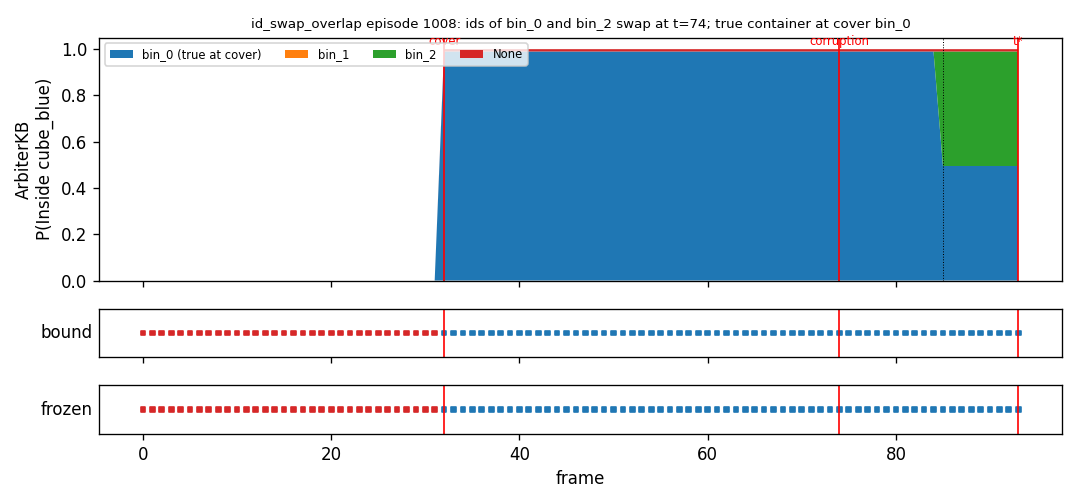

../figures/label_jumps_test_p0.5.png


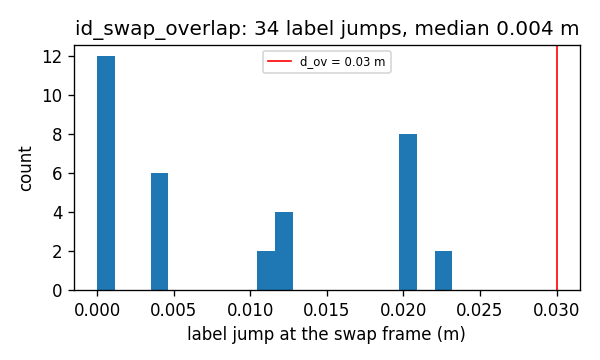

../figures/reliability_test_p0.5.png


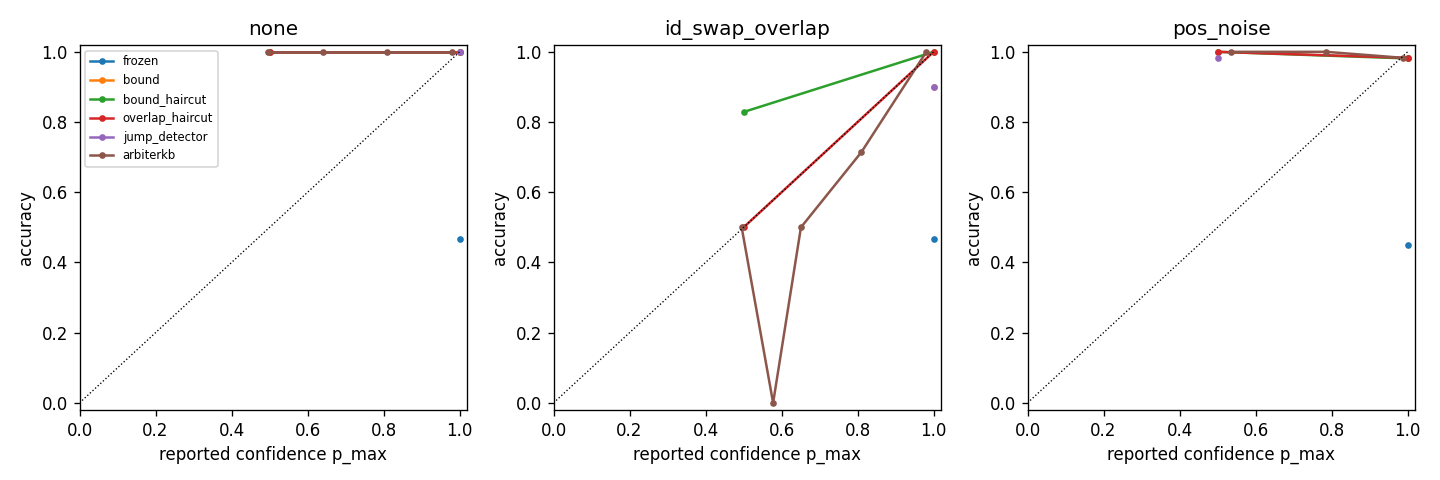

../figures/risk_coverage_test_p0.5.png


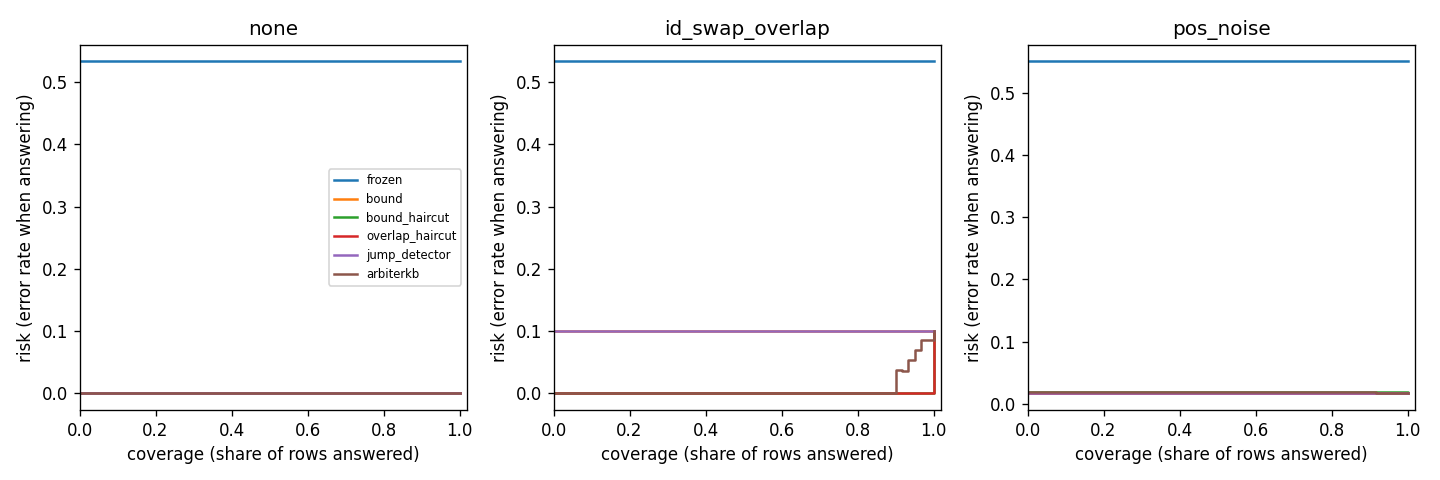

In [8]:
from IPython.display import Image, display
for f in sorted(glob.glob('../figures/*_test_p0.5.png')):
    print(f); display(Image(f))